In [1]:
import numpy as np 
import hist 
from hist import Hist

In [2]:
import uproot

file = uproot.open(
    "root://cmsxrootd.crc.nd.edu//store/user/apiccine/skimmed_SR/data/NAOD_ULv12_lepMVA-run3/2022/v260222/DoubleMuon_Run2022C_22Sep2023/output_170.root"
)

# Print the keys of the root file. Root file >> TTree >> branches
print(file.keys())

# Define the tree
tree = file["Events"]

# Print the keys of the tree. Tree >> branches
print(tree.keys())

import awkward as ak

# Convert the tree to an awkward array
events = tree.arrays(library="ak")

260610 12:41:10 2619433 crypto_Factory::GetCryptoFactory: Plugin version cryptoloader v5.8.4 is incompatible with cryptossl v5.9.2 (must be <= 5.8.x) in cryptolib libXrdCryptossl-5.so
260610 12:41:10 2619433 crypto_Factory::GetCryptoFactory: problems finding crypto factory object creator XrdCryptosslFactoryObject


['Events;1', 'LuminosityBlocks;1', 'Runs;1', 'untagged;1']
['run', 'luminosityBlock', 'event', 'bunchCrossing', 'BeamSpot_type', 'BeamSpot_sigmaZ', 'BeamSpot_sigmaZError', 'BeamSpot_z', 'BeamSpot_zError', 'nboostedTau', 'boostedTau_idAntiEle2018', 'boostedTau_idAntiMu', 'boostedTau_idMVAnewDM2017v2', 'boostedTau_idMVAoldDM2017v2', 'boostedTau_jetIdx', 'boostedTau_rawAntiEleCat2018', 'boostedTau_charge', 'boostedTau_decayMode', 'boostedTau_chargedIso', 'boostedTau_eta', 'boostedTau_leadTkDeltaEta', 'boostedTau_leadTkDeltaPhi', 'boostedTau_leadTkPtOverTauPt', 'boostedTau_mass', 'boostedTau_neutralIso', 'boostedTau_phi', 'boostedTau_photonsOutsideSignalCone', 'boostedTau_pt', 'boostedTau_puCorr', 'boostedTau_rawAntiEle2018', 'boostedTau_rawIso', 'boostedTau_rawIsodR03', 'boostedTau_rawMVAnewDM2017v2', 'boostedTau_rawMVAoldDM2017v2', 'CaloMET_phi', 'CaloMET_pt', 'CaloMET_sumEt', 'ChsMET_phi', 'ChsMET_pt', 'ChsMET_sumEt', 'nCorrT1METJet', 'CorrT1METJet_area', 'CorrT1METJet_eta', 'CorrT1METJ

## Muon pt Histogram 

/users/ldiazlie/.conda/envs/coffea-env/lib/python3.9/site-packages/mplhep/_utils.py:1111: UserWarning: Integer weights indicate poissonian data. Will calculate Garwood interval if ``scipy`` is installed. Otherwise errors will be set to ``sqrt(w2)``.
  self.errors()


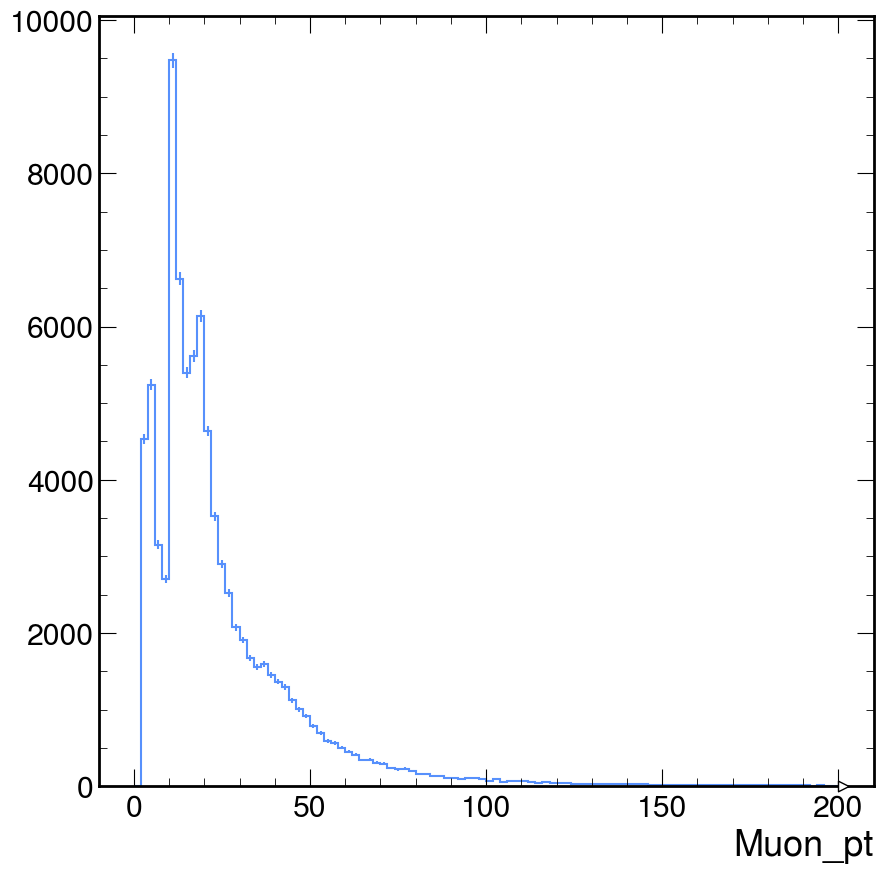

In [3]:
# Create a new histogram
import matplotlib.pyplot as plt 
import mplhep as hep

hep.style.use("CMS")

# Create the histogram on the canvas. Here we define the binning, the range, and the name of the histogram 
h = (
    Hist.new.Reg(100, 0, 200, name = "Muon_pt Histogram" , label = "Muon_pt").Double()
)

# Fill the histogram with the data
h = h.fill(ak.flatten(events["Muon_pt"]))

# Plot the histogram
h.plot()
plt.show()

## Muon Multiplicity Histogram

/users/ldiazlie/.conda/envs/coffea-env/lib/python3.9/site-packages/mplhep/_utils.py:1111: UserWarning: Integer weights indicate poissonian data. Will calculate Garwood interval if ``scipy`` is installed. Otherwise errors will be set to ``sqrt(w2)``.
  self.errors()


[StairsArtists(stairs=<matplotlib.patches.StepPatch object at 0x7f890e4f08b0>, errorbar=<ErrorbarContainer object of 3 artists>, legend_artist=<ErrorbarContainer object of 3 artists>)]

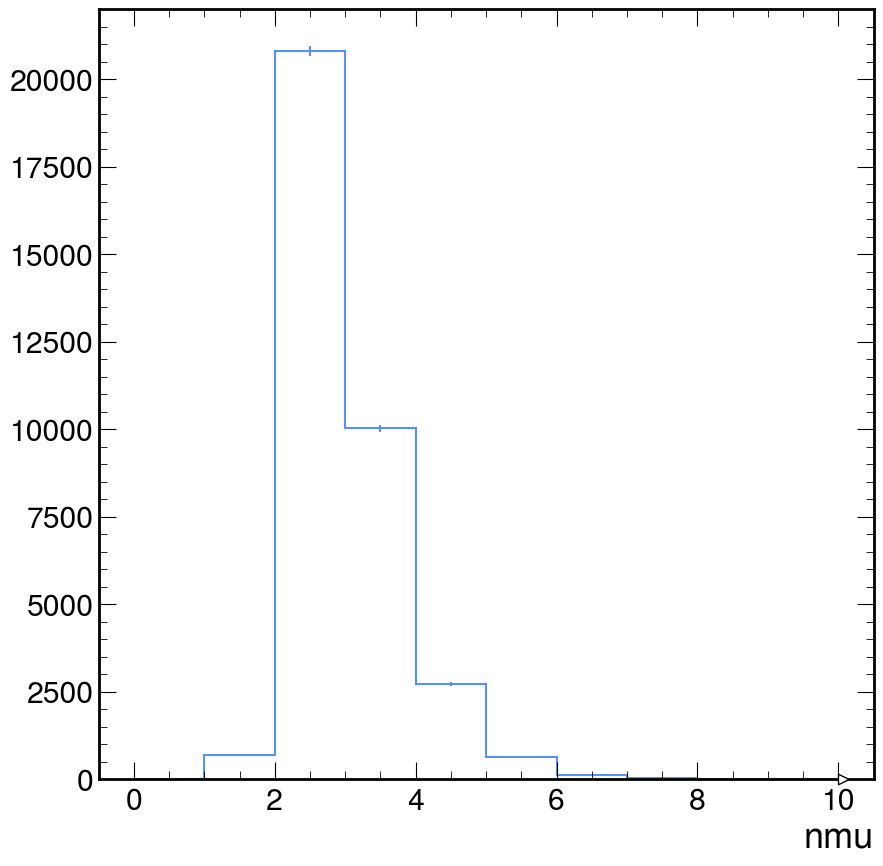

In [4]:
nmuons = ak.num(events.Muon_pt)

h_nmu = Hist.new.Reg(
    10,
    0,
    10,
    name="nmu"
).Int64()

h_nmu.fill(nmu=nmuons)


h_nmu.plot()